# AI-Powered Network Intrusion Detection System

### IBM SkillsBuild Cyber Security Bootcamp 2026

**Author:** Altamash

**Dataset:** NSL-KDD Dataset

**Machine Learning Algorithm:** Random Forest Classifier

**Project Objective:** To detect malicious network traffic using machine learning techniques and classify connections as either normal or attack traffic.

## 1. Import Required Libraries

This section imports all the libraries required for data analysis, visualisation, machine learning, and model persistence.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

## 2. Load Dataset

The NSL-KDD dataset is loaded into Pandas DataFrames for analysis and model training.

In [2]:
train_data = pd.read_csv(
    "dataset/KDDTrain+.txt",
    header=None
)

test_data = pd.read_csv(
    "dataset/KDDTest+.txt",
    header=None
)

print("Training Shape:", train_data.shape)
print("Testing Shape:", test_data.shape)


Training Shape: (125973, 43)
Testing Shape: (22544, 43)


## 3. Exploratory Data Analysis (EDA)

The following cells provide an initial overview of the dataset structure and characteristics.

In [3]:
train_data.head()

,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [4]:
train_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   0       125973 non-null  int64  
 1   1       125973 non-null  object 
 2   2       125973 non-null  object 
 3   3       125973 non-null  object 
 4   4       125973 non-null  int64  
 5   5       125973 non-null  int64  
 6   6       125973 non-null  int64  
 7   7       125973 non-null  int64  
 8   8       125973 non-null  int64  
 9   9       125973 non-null  int64  
 10  10      125973 non-null  int64  
 11  11      125973 non-null  int64  
 12  12      125973 non-null  int64  
 13  13      125973 non-null  int64  
 14  14      125973 non-null  int64  
 15  15      125973 non-null  int64  
 16  16      125973 non-null  int64  
 17  17      125973 non-null  int64  
 18  18      125973 non-null  int64  
 19  19      125973 non-null  int64  
 20  20      125973 non-null  int64  
 21  21      12

In [5]:
train_data.isnull().sum().sum()

np.int64(0)

## 4. Attack Distribution Analysis

Understanding the frequency of attack categories helps us analyse the dataset and visualise attack patterns.

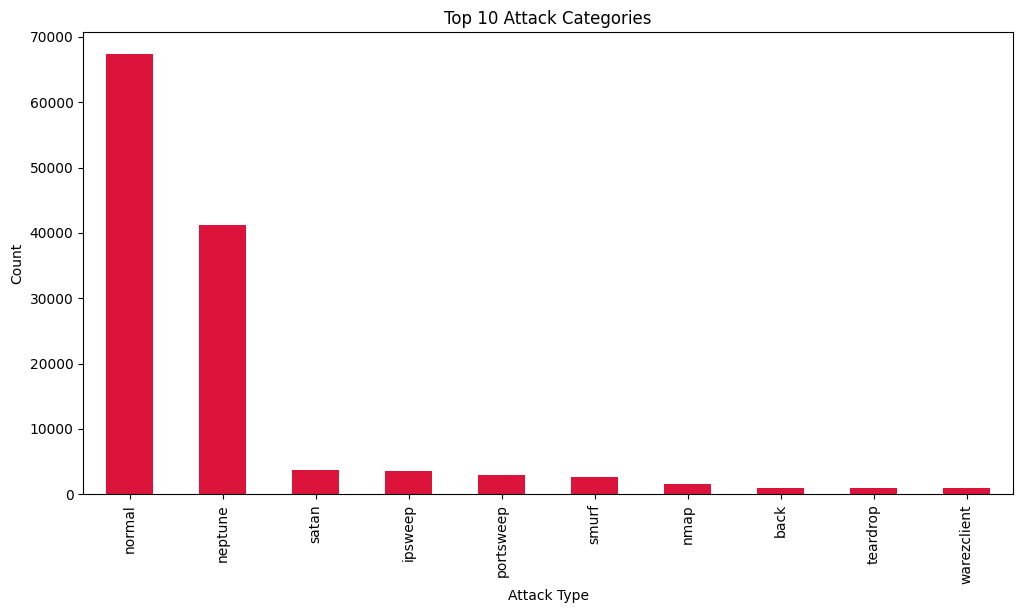

In [6]:
attack_column = train_data.columns[-2]

plt.figure(figsize=(12,6))

train_data[attack_column].value_counts().head(10).plot(
    kind="bar",
    color="crimson"
)

plt.title("Top 10 Attack Categories")
plt.xlabel("Attack Type")
plt.ylabel("Count")

plt.show()

## 5. Data Preprocessing

The attack labels are converted into binary classes:

- Normal Traffic = 0
- Attack Traffic = 1

In [7]:
train_data['label'] = train_data[41].apply(
    lambda x: 0 if x == 'normal' else 1
)

test_data['label'] = test_data[41].apply(
    lambda x: 0 if x == 'normal' else 1
)

train_data['label'].value_counts()

label
0    67343
1    58630
Name: count, dtype: int64

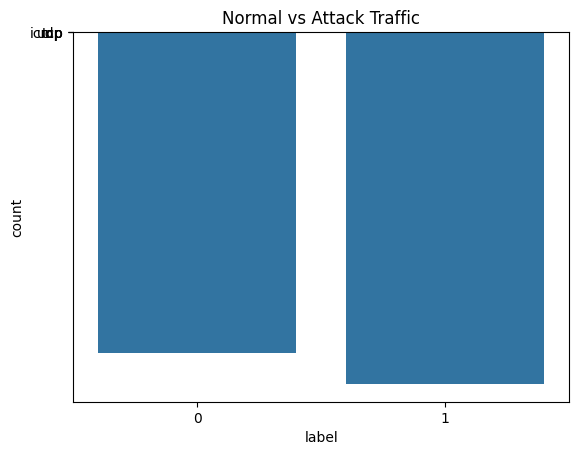

In [8]:
sns.countplot(
    x='label',
    data=train_data
)

plt.title("Normal vs Attack Traffic")
plt.show()

## 6. Feature Engineering

Remove attack-specific columns and prepare feature variables for machine learning.

In [9]:
X_train = train_data.drop([41, 42, 'label'], axis=1)
y_train = train_data['label']

X_test = test_data.drop([41, 42, 'label'], axis=1)
y_test = test_data['label']

In [10]:
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

## 7. Model Training

A Random Forest Classifier is used to learn patterns from network traffic and distinguish between normal and malicious behaviour.

In [11]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Model Training Complete")

Model Training Complete


## 8. Prediction and Evaluation

In [12]:
y_pred = rf_model.predict(X_test)


In [13]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.7730660042583393


In [14]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.66      0.97      0.79      9711
           1       0.97      0.62      0.76     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.84      0.77      0.77     22544



## 9. Confusion Matrix

The confusion matrix visualises model performance by comparing predicted labels with actual labels.

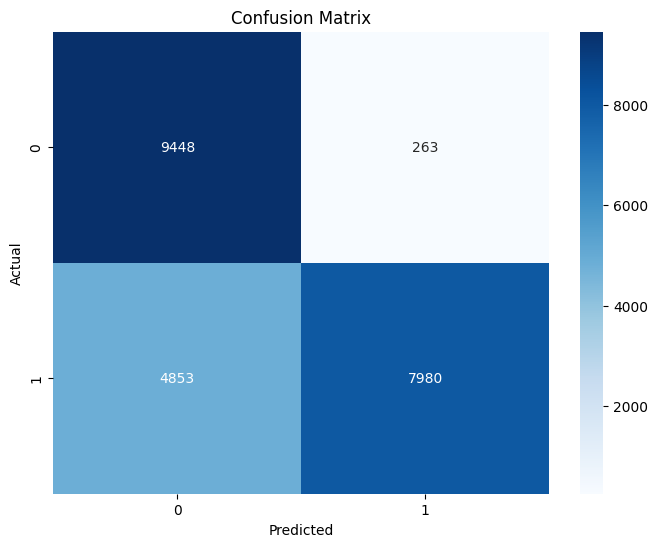

In [15]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## 10. Feature Importance Analysis

The following graph highlights the most influential network features used by the Random Forest model.

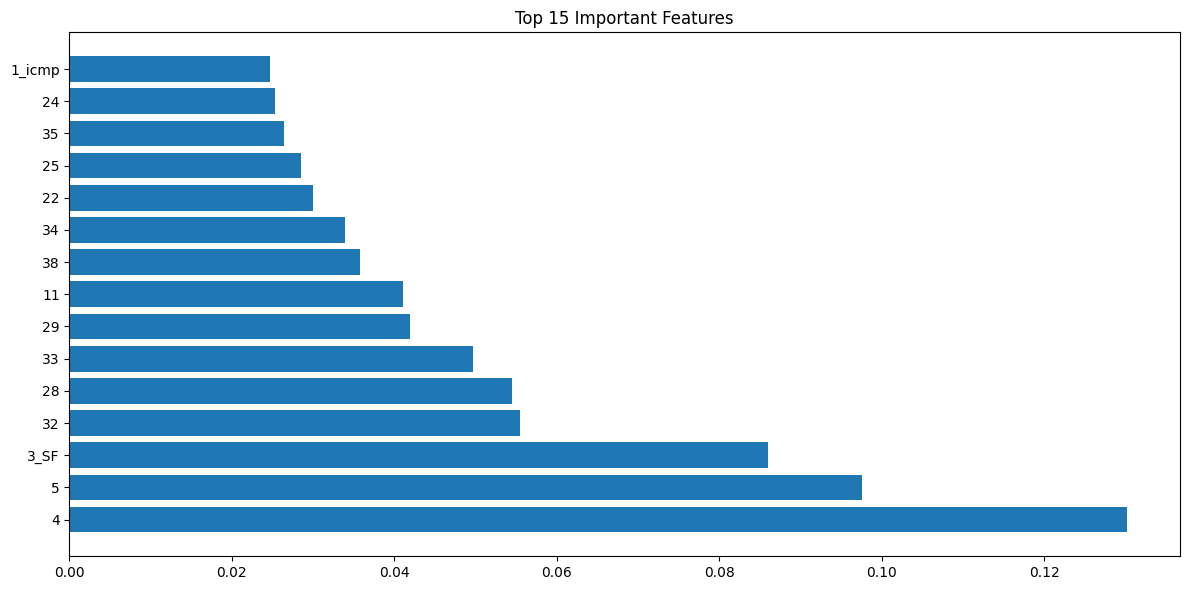

In [16]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

top_features = feature_importance.sort_values(
    by='Importance',
    ascending=False
).head(15)

plt.figure(figsize=(12,6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title("Top 15 Important Features")

plt.tight_layout()
plt.show()

## 11. Save Trained Model

The trained model is saved for future deployment and prediction tasks.

In [17]:
joblib.dump(
    rf_model,
    "models/intrusion_detection_model.pkl"
)

print("Model Saved Successfully")

Model Saved Successfully


# Conclusion

The AI-Powered Network Intrusion Detection System successfully analysed network traffic and classified connections as normal or attack traffic using a Random Forest machine learning model.

The project demonstrates the practical application of machine learning in cybersecurity and highlights how intrusion detection systems can assist organisations in identifying suspicious network behaviour.

Future improvements may include deep learning models, real-time packet analysis, and deployment as a web-based security monitoring solution.